# Bonus: How to let the model decide when to search

**CPU | API key: `OPENAI_API_KEY` (chat and embedding calls) | Self-study**

## Goal

Give the model a search tool, let it decide whether and how often to search, and judge from answers, model calls and
tokens when that beats the pipeline that searches once with the question. The moment that teaches it: a question with
two parts gets one half wrong from the fixed pipeline, because the passage for that half ranks fourth and is never
read; the model splits it into two searches and answers both parts. On a simple question it costs an extra model
call, and on a greeting it skips a search the pipeline always makes.

## What you will learn

- How a fixed search-then-answer pipeline handles a question with two parts, and a message that asks nothing.
- How to give the model a search tool and run its calls by hand, two calls in one reply included.
- How to add a stopping rule to the loop, and what a cap set too low costs.
- How to build the same loop with LangChain's `create_agent`, and read the graph it returns.
- How to compare two designs on the same questions in answers, model calls, searches and tokens, and decide which
  kind of question each one suits.

## Set up the notebook

Run these two cells first, every time; Lab 00 explains each line. **Setup** finds the repository folder (on Colab it
copies the repository and installs the packages first). **Config** reads the settings and finds your key.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Everywhere else they are installed already.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/rag_for_nlp").exists():
        !git clone -q --depth 1 https://github.com/tatwan/rag_for_nlp.git /content/rag_for_nlp
    %cd /content/rag_for_nlp
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: rag_for_nlp


In [2]:
# Config: settings from models.env (your .env and environment variables win); the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key, stamp

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name, value in stamp(settings).items():
    print(f"{name:18}{value}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

chat_model        gpt-4o-mini
reasoning_effort  None
embed_model       text-embedding-3-small
judge_model       gpt-4o-mini
rerank_model      gpt-4o-mini
chat_endpoint     https://api.openai.com/v1
embed_endpoint    https://api.openai.com/v1
run_date          2026-10-24
OPENAI_API_KEY    found in .env


This lab uses `chat_model` and `embed_model` from the lines above, and `JSON_MODE` from `models.env`. It embeds the
corpus once and makes short chat calls, well under one US cent on `gpt-4o-mini`. The saved outputs and every count in
the text come from `gpt-4o-mini`; the README says what changed with `gpt-6-luna`. Your own run will differ a little: model replies vary from run to run and similarity scores can move in the third decimal, so compare the order of results and the kind of reply with the text, not every number.

Two designs answer the same questions here. The **fixed pipeline** is Lab 05's: your code searches once with the
question, then the model answers from the top three passages. An **agent** gets a search tool instead and decides
whether to search, how often and for what.

---

## Part A: Run the fixed pipeline on three kinds of question

Part A shows what the fixed pipeline does with three kinds of message, so you know what the agent has to beat.

Build Lab 05's vector store with `shared/lc_pipeline.py`: the 272 chunks and the five policies, embedded once.

In [3]:
from shared import lc_pipeline

store = lc_pipeline.build_store(lc_pipeline.to_documents(lc_pipeline.load_corpus()), settings)
print(len(store.store), "documents in the store")

277 documents in the store


`fixed()` is the whole pipeline in three lines: search with the question (k=3), write the hits as `[ID] text` evidence
lines, and ask for a cited answer with Lab 02's rules. `show()` prints what was searched, the answer, and Lab 02's
quote check on every claim. Start with a question that has one fact:

In [4]:
from shared.answer import quote_found

def fixed(question):
    hits = lc_pipeline.retrieve(store, question)
    lines = lc_pipeline.evidence(hits)
    return hits, lines, lc_pipeline.answer(question, lines, settings)

def show(question):
    hits, lines, reply = fixed(question)
    print("passages:", [document.id for document, _ in hits])
    print("answer:  ", reply.answer)
    for claim in reply.claims:
        print(f"  [{claim.source_id}] quote found {quote_found(claim.model_dump(), lines)}: {claim.quote[:70]}")

show("Who was the Super Bowl 50 MVP?")

passages: ['S00-P00-C00', 'S00-P02-C00', 'S00-P01-C00']
answer:   Von Miller was the Super Bowl 50 MVP.
  [S00-P02-C00] quote found True: Denver linebacker Von Miller was named Super Bowl MVP, recording five 


One search, three passages, and *Von Miller was the Super Bowl 50 MVP.*, its quote found in S00-P02-C00. One
question, one fact, one search: the case the pipeline is built for.

Now a question with two parts, both answered in the corpus: Richard I ruled the duchy, and the Latin form of *Norman*
was first recorded in the 9th century. Run it three times:

In [5]:
NORMANDY = "Who ruled the duchy of Normandy, and when was the Latin version of the word Norman first recorded?"
for _ in range(3):
    show(NORMANDY)

passages: ['S02-P01-C01', 'S02-P01-C00', 'S02-P00-C00']
answer:   The duchy of Normandy was ruled under Richard I of Normandy, and the Latin version of the word Norman was first recorded in the 10th and 11th centuries.
  [S02-P01-C01] quote found True: under Richard I of Normandy was forged into a cohesive and formidable 
  [S02-P00-C00] quote found True: The Normans (Norman: Nourmands; French: Normands; Latin: Normanni) wer


passages: ['S02-P01-C01', 'S02-P01-C00', 'S02-P00-C00']
answer:   The duchy of Normandy was ruled under Richard I of Normandy, and the Latin version of the word Norman was first recorded in the 10th and 11th centuries.
  [S02-P01-C01] quote found True: under Richard I of Normandy was forged into a cohesive and formidable 
  [S02-P00-C00] quote found True: The Normans (Norman: Nourmands; French: Normands; Latin: Normanni) wer


passages: ['S02-P01-C01', 'S02-P01-C00', 'S02-P00-C00']
answer:   The duchy of Normandy was ruled under Richard I of Normandy, and the Latin version of the word Norman was first recorded in the 10th and 11th centuries.
  [S02-P01-C01] quote found True: under Richard I of Normandy was forged into a cohesive and formidable 
  [S02-P00-C00] quote found True: The Normans (Norman: Nourmands; French: Normands; Latin: Normanni) wer


All three runs search once with the whole question and get the same three passages: two about the duchy and one about
who the Normans were (S02-P00-C00). Every answer names Richard I, which is right, and says the Latin form was first
recorded *in the 10th and 11th centuries*, which is wrong. That claim cites S02-P00-C00 with a quote that is found:
the passage does say *Latin: Normanni* and *in the 10th and 11th centuries*, but the centuries are when the Normans
gave their name to Normandy. Lab 02's checks pass a wrong answer, because every word they check is in the evidence.

Where is the passage that holds the 9th century? Rank ten passages for the question and print that one:

In [6]:
ranked = [document.id for document, _ in lc_pipeline.retrieve(store, NORMANDY, k=10)]
print(ranked)
print("S02-P02-C00 ranks", ranked.index("S02-P02-C00") + 1)
print(store.get_by_ids(["S02-P02-C00"])[0].page_content)

['S02-P01-C01', 'S02-P01-C00', 'S02-P00-C00', 'S02-P02-C00', 'S02-P00-C01', 'S02-P01-C02', 'S22-P01-C00', 'S10-P02-C00', 'S22-P02-C00', 'S06-P02-C00']
S02-P02-C00 ranks 4
The English name "Normans" comes from the French words Normans/Normanz, plural of Normant, modern French normand, which is itself borrowed from Old Low Franconian Nortmann "Northman" or directly from Old Norse Norðmaðr, Latinized variously as Nortmannus, Normannus, or Nordmannus (recorded in Medieval Latin, 9th century) to mean "Norseman, Viking".


S02-P02-C00 ranks fourth, one place outside the top three, and it says *recorded in Medieval Latin, 9th century*. The
model filled the gap from the nearest passage that mentions Latin and centuries. A fixed search cannot know that this
question needs two.

The third kind is a message that asks nothing. A help desk gets greetings and thanks as well as questions:

In [7]:
show("Hi there!")

passages: ['S34-P00-C00', 'S34-P00-C01', 'H02']
answer:   Insufficient evidence.


The pipeline searched for *Hi there!* anyway, got two passages from S34 and the policy H02, and answered
*Insufficient evidence.* It makes one search and one call for every message, and its rules allow only an answer from
the evidence or the refusal.

### Checkpoint A

| You should see | Our run |
|---|---|
| The store | 277 documents |
| *Who was the Super Bowl 50 MVP?* | S00-P00-C00, S00-P02-C00, S00-P01-C00; *Von Miller was the Super Bowl 50 MVP.*, quote found |
| The Normandy question | S02-P01-C01, S02-P01-C00, S02-P00-C00 every run; Richard I and *the 10th and 11th centuries*, both quotes found, 3 of 3 |
| The answering passage | S02-P02-C00 fourth, *9th century* in its text |
| *Hi there!* | one search; *Insufficient evidence.* |

---

## Part B: Give the model a search tool and run its calls by hand

Part B lets the model choose the searches. Lab 09 built each piece: `@tool` turns a function into a tool whose
docstring the model reads, `bind_tools()` attaches it to every call, and `tool.invoke(tool_call)` runs a call and
returns a `ToolMessage` with the call's ID. The instruction now says the model may search more than once. Send it the
Normandy question:

In [8]:
from langchain.tools import tool
from shared.settings import lc_chat_model, chat_url

@tool
def search_documents(query: str) -> str:
    """Search the documents and return the three closest passages as [ID] text lines."""
    return "\n".join(lc_pipeline.evidence(lc_pipeline.retrieve(store, query)))

SYSTEM = ("Answer questions from the documents. Use search_documents to find passages; you may search more than once."
          " Answer only from the passages and cite their IDs in brackets."
          " If the passages do not answer, say: Insufficient evidence.")
chat = lc_chat_model("CHAT_MODEL", settings)
with_search = chat.bind_tools([search_documents])
messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": NORMANDY}]
reply = with_search.invoke(messages)
print("text:", repr(reply.content))
for call in reply.tool_calls:
    print("tool call:", call["args"], call["id"])

text: ''
tool call: {'query': 'ruled the duchy of Normandy'} call_sxoOXUVBPUwF6eIdspoFM4cW
tool call: {'query': 'Latin version of the word Norman first recorded'} call_FSn1p4XC36sNQDLZlPqIiKUf


The reply has no text and two tool calls, each with its own ID: *ruled the duchy of Normandy* and *Latin version of
the word Norman first recorded*. The model split the question into its parts and asked for both searches in one
reply. The API calls these **parallel tool calls**.

Nothing has searched yet. Run each call, add its result to the conversation after the model's reply, and send it all
back. The API refuses the next call unless every tool call has its result (see Troubleshooting):

In [9]:
import re

messages.append(reply)
for call in reply.tool_calls:
    result = search_documents.invoke(call)
    messages.append(result)
    print(f"{call['args']['query']!r} found", re.findall(r"^\[(.+?)\]", result.content, re.M))

final = with_search.invoke(messages)
print("tool calls:", final.tool_calls)
print(final.content)

'ruled the duchy of Normandy' found ['S02-P01-C01', 'S02-P01-C00', 'S02-P00-C00']


'Latin version of the word Norman first recorded' found ['S02-P02-C00', 'S02-P00-C00', 'S02-P01-C00']


tool calls: []
The duchy of Normandy was ruled by Richard I of Normandy, who played a significant role in forging it into a cohesive and formidable principality in feudal tenure [S02-P01-C01].

The Latin version of the word "Norman" was first recorded in the 9th century, where it appeared as "Nortmannus," "Normannus," or "Nordmannus," meaning "Norseman" or "Viking" [S02-P02-C00].


The second search found S02-P02-C00 first, the passage the pipeline ranked fourth. The last reply has no tool calls,
so it is the answer: Richard I, citing S02-P01-C01, and *the 9th century*, citing S02-P02-C00. Two model calls, two
searches.

A reply can ask for more searches instead of answering, so the round trip goes in a loop: run every tool call, send
the results back, and stop when a reply has none. This is Lab 09's loop; `run_agent()` also counts the model calls
and keeps the queries. Run it on Part A's other two messages:

In [10]:
def run_agent(question):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    reply = with_search.invoke(messages)
    calls, queries = 1, []
    while reply.tool_calls:
        messages.append(reply)
        for call in reply.tool_calls:
            queries.append(call["args"]["query"])
            messages.append(search_documents.invoke(call))
        reply = with_search.invoke(messages)
        calls += 1
    return queries, calls, reply.content

for question in ("Who was the Super Bowl 50 MVP?", "Hi there!"):
    print(*run_agent(question), sep=" | ")

['Super Bowl 50 MVP'] | 2 | The Super Bowl 50 MVP was Von Miller, who recorded five solo tackles, 2½ sacks, and two forced fumbles during the game [S00-P02-C00].


[] | 1 | Hello! How can I assist you today?


On the Super Bowl question the model searched once (*Super Bowl 50 MVP*) and answered Von Miller: two model calls
where the pipeline made one. On *Hi there!* it did not search and replied *Hello! How can I assist you today?* in one
call.

### Checkpoint B

| You should see | Our run |
|---|---|
| The first reply to the Normandy question | no text, two tool calls: *ruled the duchy of Normandy*, *Latin version of the word Norman first recorded* |
| The answer after both searches | S02-P02-C00 first for the second query; Richard I and *the 9th century* |
| `run_agent()` on the Super Bowl question | `['Super Bowl 50 MVP']`, 2 calls, Von Miller |
| `run_agent()` on *Hi there!* | `[]`, 1 call, *Hello! How can I assist you today?* |

---

## Part C: Add a stopping rule

Part C puts a limit on the loop in code. `run_agent()` stops only when the model stops asking, so the model decides
how many searches a question gets. Ask about something the documents do not cover, three times:

In [11]:
REFUND = "What is the refund policy for Boreal?"
for _ in range(3):
    print(*run_agent(REFUND), sep=" | ")

['refund policy Boreal', 'Boreal return policy'] | 3 | Insufficient evidence.


['refund policy Boreal', 'Boreal return policy'] | 3 | Insufficient evidence.


['refund policy Boreal', 'Boreal return policy'] | 3 | Insufficient evidence.


No document covers refunds. Each run searched twice, *refund policy Boreal* and then *Boreal
return policy*, found nothing that answers, and refused: three model calls for the refusal.

Here the model stopped by itself. Nothing in the loop would stop a model that kept searching, and every round is one
more model call with a longer conversation. A **stopping rule** is a limit your code enforces: at most `max_searches`
searches per question. Past it, each call still gets a `ToolMessage`, as the API requires, saying the limit is
reached, so the model answers from what it has:

In [12]:
from langchain_core.messages import ToolMessage

LIMIT = "Search limit reached. Answer from the passages you already have."

def run_agent(question, max_searches=3):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    reply = with_search.invoke(messages)
    calls, queries = 1, []
    while reply.tool_calls:
        messages.append(reply)
        for call in reply.tool_calls:
            if len(queries) < max_searches:
                queries.append(call["args"]["query"])
                messages.append(search_documents.invoke(call))
            else:
                messages.append(ToolMessage(LIMIT, tool_call_id=call["id"]))
        reply = with_search.invoke(messages)
        calls += 1
    return queries, calls, reply.content

A limit has to be tested where it bites. Set it to one search, and run the refund question and the Normandy question
three times each:

In [13]:
for question in (REFUND, NORMANDY):
    for _ in range(3):
        print(*run_agent(question, max_searches=1), sep=" | ")

['refund policy Boreal'] | 3 | Insufficient evidence.


['refund policy Boreal'] | 3 | Insufficient evidence.


['refund policy Boreal'] | 3 | Insufficient evidence.


['ruled the duchy of Normandy'] | 2 | The duchy of Normandy was ruled by Richard I of Normandy, who played a significant role in forging it into a cohesive and formidable principality in feudal tenure [S02-P01-C01].

The Latin version of the word "Norman" is "Normanni," which is derived from the term "Norseman," indicating the descent of the Normans from Norse raiders and pirates [S02-P00-C00]. However, the specific date of the first recorded use of the Latin version is not provided in the passages.


['ruled the duchy of Normandy'] | 2 | The duchy of Normandy was ruled by Richard I of Normandy, who played a significant role in forging it into a cohesive and formidable principality in feudal tenure [S02-P01-C01].

The Latin version of the word "Norman" is "Normanni," which is derived from the term "Norseman," indicating the descent of the Normans from Norse raiders and pirates [S02-P00-C00]. However, the specific date of the first recorded use of the Latin version is not provided in the passages.


['ruled the duchy of Normandy'] | 2 | The duchy of Normandy was ruled by Richard I of Normandy, who played a significant role in forging it into a cohesive and formidable principality in feudal tenure [S02-P01-C01].

The Latin version of the word "Norman" is "Normanni," which is derived from the term "Norseman," indicating the descent of the Normans from Norse raiders and pirates [S02-P00-C00]. However, the specific date of the first recorded use of the Latin version is not provided in the passages.


The refund question still refuses 3 of 3, in three calls: the model asked for a second search, got `LIMIT` back, and
answered. The Normandy question lost its second search: each run searched only *ruled the duchy of Normandy* and gave
the Latin form no date, 3 of 3, and two of the answers say the date is not in the passages. One search puts the agent
back at the pipeline's half answer, though it now says what it lacks.

A stopping rule is a guard against a loop that runs away, not a budget to squeeze: set it above what your questions
need. No question so far needed more than two searches, so the lab keeps the default of three.

### Checkpoint C

| You should see | Our run |
|---|---|
| The refund question, no limit | two searches and three calls per run, *Insufficient evidence.* 3 of 3 |
| The refund question, one search | one search and three calls per run, *Insufficient evidence.* 3 of 3 |
| The Normandy question, one search | one search (*ruled the duchy of Normandy*), Richard I, no date for the Latin form, 3 of 3 |

---

## Part D: Build the same loop with `create_agent`

Part D hands the loop to LangChain. [`create_agent`](https://docs.langchain.com/oss/python/langchain/agents) takes
the model, the tools and the system prompt, and runs the steps `run_agent()` runs. Build it and display what it
returns:

CompiledStateGraph | recursion limit: 9999


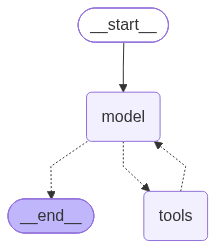

In [14]:
from langchain.agents import create_agent

agent = create_agent(chat, tools=[search_documents], system_prompt=SYSTEM)
print(type(agent).__name__, "| recursion limit:", agent.config["recursion_limit"])
agent

The agent is a `CompiledStateGraph` from LangGraph, the runtime under LangChain's agents, and the picture is your
loop. `model` calls the model. The dotted arrows are the model's choice: to `tools` when its reply has tool calls, to
`__end__` when it has none. `tools` runs every call, and its arrow back to `model` is your `while`. (If the picture
fails to draw, see Troubleshooting.)

Run the Normandy question through it. `show_messages()` prints each message's type with its tool calls or the start of
its text, then the answer in full:

In [15]:
def show_messages(messages):
    for message in messages[:-1]:
        calls = [call["args"] for call in getattr(message, "tool_calls", [])]
        print(f"{message.type:5} |", calls or message.text[:110].replace("\n", " "))
    print(messages[-1].text)

show_messages(agent.invoke({"messages": [{"role": "user", "content": NORMANDY}]})["messages"])

human | Who ruled the duchy of Normandy, and when was the Latin version of the word Norman first recorded?
ai    | [{'query': 'ruled the duchy of Normandy'}, {'query': 'Latin version of the word Norman first recorded'}]
tool  | [S02-P01-C01] an important literary language. The Duchy of Normandy, which they formed by treaty with the Fren
tool  | [S02-P02-C00] The English name "Normans" comes from the French words Normans/Normanz, plural of Normant, moder
The duchy of Normandy was ruled by Richard I of Normandy, who played a significant role in forging it into a cohesive and formidable principality in feudal tenure [S02-P01-C01].

The Latin version of the word "Norman" was first recorded in the 9th century, where it appeared as "Nortmannus," "Normannus," or "Nordmannus," meaning "Norseman" or "Viking" [S02-P02-C00].


The messages follow your loop step by step: the question, an AI message with the two queries from Part B, two tool
messages (S02-P01-C01 and S02-P02-C00 first), and the answer with Richard I and *the 9th century*.

The only limit `create_agent` sets is the recursion limit printed above: 9,999 graph steps. A model that kept
searching would make thousands of calls before LangGraph stopped it with an error. Your stopping rule goes in as a
**middleware**: a step LangChain runs around the model or the tools on every turn.
`ToolCallLimitMiddleware(run_limit=...)` counts tool calls per question and, past the limit, answers each new call
with a message instead of running it, as `LIMIT` did. Check it with a limit of one on the Normandy question:

In [16]:
from langchain.agents.middleware import ToolCallLimitMiddleware

tight = create_agent(chat, tools=[search_documents], system_prompt=SYSTEM,
                     middleware=[ToolCallLimitMiddleware(run_limit=1)])
show_messages(tight.invoke({"messages": [{"role": "user", "content": NORMANDY}]})["messages"])

human | Who ruled the duchy of Normandy, and when was the Latin version of the word Norman first recorded?
ai    | [{'query': 'who ruled the duchy of Normandy'}, {'query': 'Latin version of the word Norman first recorded'}]
tool  | Tool call limit exceeded. Do not make additional tool calls.
tool  | [S02-P01-C01] an important literary language. The Duchy of Normandy, which they formed by treaty with the Fren
ai    | [{'query': 'who ruled the duchy of Normandy'}, {'query': 'Latin version of the word Norman first recorded'}]
tool  | Tool call limit exceeded. Do not make additional tool calls.
tool  | Tool call limit exceeded. Do not make additional tool calls.
The duchy of Normandy was ruled by Richard I of Normandy, who played a significant role in forging it into a cohesive principality in feudal tenure [S02-P01-C01].

As for the Latin version of the word "Norman," the specific date of its first recording is not provided in the passages. Therefore, I cannot provide that information. In

The first reply asks for the same two searches. The middleware ran the first (its result starts with S02-P01-C01, as
in Part B) and answered the second with *Tool call limit exceeded. Do not make additional tool calls.* In our run the model then asked for both searches again and got the same message twice. The answer
names Richard I and says the date of the Latin form is not in the passages, as with Part C's limit of one.

The agent Part E compares keeps the limit at three. The middleware adds one node to the graph:

In [17]:
agent = create_agent(chat, tools=[search_documents], system_prompt=SYSTEM,
                     middleware=[ToolCallLimitMiddleware(run_limit=3)])
print(list(agent.get_graph().nodes))

['__start__', 'model', 'tools', 'ToolCallLimitMiddleware.after_model', '__end__']


`ToolCallLimitMiddleware.after_model` runs after every model call and checks the count before `tools` runs.

### Checkpoint D

| You should see | Our run |
|---|---|
| The agent | `CompiledStateGraph`, recursion limit 9999, drawn as `model` and `tools` with a loop between them |
| The Normandy question | two queries in one AI message, two tool messages, Richard I and *the 9th century* |
| With `run_limit=1` | *Tool call limit exceeded. Do not make additional tool calls.* for one call; no date for the Latin form |
| The graph with the limit | five nodes: `__start__`, `model`, `tools`, `ToolCallLimitMiddleware.after_model`, `__end__` |

---

## Part E: Compare the two designs on the same questions

Part E runs both designs on eight messages, three times each, and counts what each run cost and whether it was
right.

Each message lists the facts a right answer must contain, one list of accepted answers per part. The two-part
questions are Part A's Normandy question, a question that joins two unrelated facts, and a pair of policy questions
that one search can answer:

In [18]:
QUESTIONS = [
    ("one fact", "Who was the Super Bowl 50 MVP?", [["Von Miller"]]),
    ("one fact", "In what year was Nikola Tesla born?", [["1856"]]),
    ("one fact", "Who can export all reports in Atlas?", [["workspace owners"]]),
    ("two parts", NORMANDY, [["Richard I"], ["9th century"]]),
    ("two parts", "Who was the Super Bowl 50 MVP, and who can export all reports in Atlas?",
     [["Von Miller"], ["workspace owners"]]),
    ("two parts", "How long is an Atlas reset link valid, and how long is a Boreal one?", [["30 minutes"], ["10 minutes"]]),
    ("no search", "Hi there!", []),
    ("no search", "Thanks, that is all I needed.", []),
]
print(len(QUESTIONS), "messages:", sorted({kind for kind, _, _ in QUESTIONS}))

8 messages: ['no search', 'one fact', 'two parts']


Three things are counted per run:

- **Right.** Every part's answer is in the reply, checked with Lab 06's `found()` (a whole accepted answer inside the
  normalised reply). A message with no parts is right when the reply does not refuse.
- **Model calls and searches.** One each for the pipeline, by its code; for the agent, the AI messages in its result
  and their tool calls.
- **Tokens.** `get_usage_metadata_callback()` adds up the `usage` of every LangChain model call made inside it, the one
  inside `lc_pipeline.answer()` included, as tokens sent (in) and written (out).

Each design becomes a function that returns the answer, the queries and the model calls:

In [19]:
from langchain_core.callbacks import get_usage_metadata_callback
from shared.evals import REFUSAL, found

def fixed_design(question):
    hits, lines, reply = fixed(question)
    return reply.answer, [question], 1

def agent_design(question):
    messages = agent.invoke({"messages": [{"role": "user", "content": question}]})["messages"]
    replies = [message for message in messages if message.type == "ai"]
    return messages[-1].text, [call["args"]["query"] for reply in replies for call in reply.tool_calls], len(replies)

def run(design, question, parts):
    with get_usage_metadata_callback() as usage:
        answer, queries, calls = design(question)
    tokens = [sum(u[kind] for u in usage.usage_metadata.values()) for kind in ("input_tokens", "output_tokens")]
    right = all(found(answer, part) for part in parts) if parts else REFUSAL not in answer
    return {"right": right, "calls": calls, "searches": len(queries), "tokens": tokens, "queries": queries,
            "answer": answer}

Run every message three times through each design, and print each run:

In [20]:
rows = []
for kind, question, parts in QUESTIONS:
    print(question)
    for name, design in (("fixed", fixed_design), ("agent", agent_design)):
        for _ in range(3):
            row = {"kind": kind, "design": name, **run(design, question, parts)}
            rows.append(row)
            answer = row["answer"].replace("\n", " ")[:80]
            print(f"  {name:6}{'right' if row['right'] else 'wrong':6}{row['calls']} calls {row['searches']} searches "
                  f"{sum(row['tokens']):5} tokens | {row['queries'] if name == 'agent' else ''} {answer!r}")

Who was the Super Bowl 50 MVP?


  fixed right 1 calls 1 searches   601 tokens |  'Von Miller was the Super Bowl 50 MVP.'


  fixed right 1 calls 1 searches   601 tokens |  'Von Miller was the Super Bowl 50 MVP.'


  fixed right 1 calls 1 searches   601 tokens |  'Von Miller was the Super Bowl 50 MVP.'


  agent right 2 calls 1 searches   600 tokens | ['Super Bowl 50 MVP'] 'The Super Bowl 50 MVP was Von Miller, who recorded five solo tackles, 2½ sacks, '


...

  fixed wrong 1 calls 1 searches   304 tokens |  'Insufficient evidence.'


  fixed wrong 1 calls 1 searches   304 tokens |  'Insufficient evidence.'


  agent wrong 1 calls 0 searches   111 tokens | [] 'Insufficient evidence.'


  agent wrong 1 calls 0 searches   111 tokens | [] 'Insufficient evidence.'


  agent wrong 1 calls 0 searches   111 tokens | [] 'Insufficient evidence.'


Every run is printed, so you can read the answer behind each count. On *Who was the Super Bowl 50 MVP, and who can
export all reports in Atlas?* the pipeline answers only the Super Bowl half and drops the other without a word, 3 of
3. The agent searches once per part on every two-part question, and answers the thank-you with *Insufficient
evidence.* without searching, 3 of 3.

Now add the runs up by kind of message and design:

In [21]:
print(f"{'kind':11}{'design':8}{'right':>9}{'model calls':>13}{'searches':>10}{'tokens in':>11}{'tokens out':>12}")
for kind in ("one fact", "two parts", "no search"):
    for name in ("fixed", "agent"):
        group = [row for row in rows if row["kind"] == kind and row["design"] == name]
        print(f"{kind:11}{name:8}{sum(row['right'] for row in group):>4} of {len(group)}"
              f"{sum(row['calls'] for row in group):>13}{sum(row['searches'] for row in group):>10}"
              f"{sum(row['tokens'][0] for row in group):>11}{sum(row['tokens'][1] for row in group):>12}")
print(f"\n{settings['CHAT_MODEL']} at {chat_url(settings)}")

kind       design      right  model calls  searches  tokens in  tokens out
one fact   fixed      9 of 9            9         9       3981         481
one fact   agent      9 of 9           18         9       4056         381
two parts  fixed      3 of 9            9         9       4242         968
two parts  agent      9 of 9           18        18       6123        1027
no search  fixed      0 of 6            6         6       2061          60
no search  agent      3 of 6            6         0        621          45

gpt-4o-mini at https://api.openai.com/v1


Kind by kind:

- **One fact.** Both designs are right 9 of 9. The agent makes 18 model calls to the pipeline's 9, yet sends about the
  same tokens (4,056 in against 3,981) and writes fewer (about 380 against 480). Its first call carries only the
  question and the tool, and its answer is one sentence with an ID, where the pipeline writes claims with quotes. On
  these questions the agent's price is a second round trip, not tokens.
- **Two parts.** The agent is right 9 of 9, the pipeline 3 of 9. The agent pays 18 searches and 18 calls against 9
  and 9, and 6,123 tokens in against 4,242, about 44 percent more.
- **No search.** The pipeline searched six times for messages that ask nothing and refused all six (2,061 tokens in).
  The agent never searched (621 tokens in) and was right on the greeting only: the instruction's abstention line also
  caught *Thanks, that is all I needed.*

So the agent earns its extra call on a question with more than one part, and on a message with none; on a one-fact
question whose passage reaches the top three, the fixed pipeline does as well with one call. Two costs the table does
not show: every extra call is one more wait for a reply, and the agent answers in text with IDs, not quoted claims, so
Lab 03's quote check has nothing to check. A help desk that gets mostly single-fact questions can keep the fixed
pipeline; compound questions and small talk are where an agent pays for itself.

### Checkpoint E

| You should see | Our run |
|---|---|
| One fact | both 9 of 9; 9 against 18 model calls; 3,981 against 4,056 tokens in |
| Two parts | fixed 3 of 9, agent 9 of 9; 9 against 18 searches; 4,242 against 6,123 tokens in |
| No search | fixed 0 of 6 after 6 searches; agent right on *Hi there!* (3 of 3) with no search, *Insufficient evidence.* for the thank-you |

---

## What you can do now

- Show where a fixed pipeline fails on a two-part question while every citation check passes, and what it does with
  a greeting.
- Give the model a search tool and run its calls by hand, two in one reply included, in a loop.
- Add a stopping rule to the loop, and test it where it bites.
- Build the same agent with `create_agent` and `ToolCallLimitMiddleware`, and read its graph.
- Compare two designs in answers, model calls, searches and tokens, and say which kind of question each suits.

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor. Task 1 is the challenge; task 2
is optional. For each task, keep the printed results and your answer to **Explain**.

1. **Ask a question with three parts.** *Who was the Super Bowl 50 MVP, in what year was Nikola Tesla born, and who can
   export all reports in Atlas?*

   - Under **Task 1**, set `THREE_PARTS` to the question and `PARTS` to one list of accepted answers per part. The cell
     runs it three times through each design with `run()`.

   **Check:** right or not, searches and tokens per run. Our worked solution: the pipeline answered the Super Bowl
   and Tesla parts and said *the evidence does not specify who can export all reports in Atlas*, 3 of 3, from
   passages S03-P00-C00, S00-P02-C00 and S00-P00-C00. The agent made three searches in every run, one per part, and
   was right 3 of 3, at about 1,100 tokens a run against about 650.

   **Explain:** which part did the pipeline miss, and why (print its passages)? How close did the agent come to its
   limit of three searches, and what would one more part do?

2. **Optional: let the agent answer small talk.** The agent refused *Thanks, that is all I needed.* in Part E.

   - Under **Task 2**, set `SMALL_TALK` to one line added to `SYSTEM`, for example *Reply to greetings and thanks in one
     short sentence, without searching.* The cell builds a new agent with it and runs the no-search and
     one-fact messages three times each.

   **Check:** every answer and its searches, not only the thank-you. Our worked solution, with the example line: the
   thank-you got *You're welcome! ...* (3 of 3) and the greeting was unchanged. The Super Bowl and Tesla questions were
   refused without a search, 3 of 3 each (in an earlier run the model answered Tesla from its own memory, with no ID,
   2 of 3). Only the Atlas question still searched.

   **Explain:** which rows did the new line fix, which did it break, and why would Part E's no-search rows alone not
   have told you?

**Task 1.** Your question and its parts, then both designs:

In [22]:
THREE_PARTS = None    # TODO: the question from the task, as a string
PARTS = None          # TODO: one list of accepted answers per part, as in QUESTIONS

if THREE_PARTS is None or PARTS is None:
    print("⚠️ Set THREE_PARTS and PARTS, then run the cell again.")
else:
    print("pipeline passages:", [document.id for document, _ in lc_pipeline.retrieve(store, THREE_PARTS)])
    for name, design in (("fixed", fixed_design), ("agent", agent_design)):
        for _ in range(3):
            row = run(design, THREE_PARTS, PARTS)
            answer = row["answer"].replace("\n", " ")[:150]
            print(f"{name:6}{'right' if row['right'] else 'wrong':6}{row['searches']} searches {sum(row['tokens']):5} tokens"
                  f" | {row['queries'] if name == 'agent' else ''} {answer!r}")

⚠️ Set THREE_PARTS and PARTS, then run the cell again.


**Task 2 (optional).** Your line, then the five messages:

In [23]:
SMALL_TALK = None    # TODO: one line to add to SYSTEM, as a string

if SMALL_TALK is None:
    print("⚠️ Set SMALL_TALK, then run the cell again.")
else:
    polite = create_agent(chat, tools=[search_documents], system_prompt=SYSTEM + " " + SMALL_TALK,
                          middleware=[ToolCallLimitMiddleware(run_limit=3)])
    for kind, question, parts in QUESTIONS:
        if kind in ("no search", "one fact"):
            for _ in range(3):
                messages = polite.invoke({"messages": [{"role": "user", "content": question}]})["messages"]
                queries = [call["args"]["query"] for message in messages if message.type == "ai" for call in message.tool_calls]
                print(f"{question[:36]:38}{queries!s:32}{messages[-1].text[:70]!r}")

⚠️ Set SMALL_TALK, then run the cell again.


## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `OpenAIInvalidRequestError: Error code: 400 ... An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'.` | a reply with two tool calls was sent back with a result for only one of them | Append a `ToolMessage` for every call in `reply.tool_calls`, a limit message included, before the next `invoke()` |
| `GraphRecursionError: Recursion limit of 2 reached without hitting a stop condition.` | a `{"recursion_limit": 2}` in the `invoke` config: it counts graph steps, and one search round takes two | Limit the searches with `ToolCallLimitMiddleware`, which lets the model answer; keep the recursion limit well above the steps a question needs |
| `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph` when you display `agent` | the picture is drawn by the mermaid.ink web service, which your network blocks | `print(agent.get_graph().draw_mermaid())` prints the same graph as text, with no network call |
| `OpenAIInvalidRequestError: Error code: 400 ... Function tools with reasoning_effort are not supported for gpt-6-luna in /v1/chat/completions.` | `REASONING_EFFORT` is `low`, `medium` or `high` for a reasoning model | Set `REASONING_EFFORT=none` in `.env`: Chat Completions takes tools on `gpt-6-luna` only at that effort |

## Resources

- [LangChain: retrieval](https://docs.langchain.com/oss/python/langchain/retrieval): 2-step RAG against agentic RAG,
  where the model decides when to retrieve
- [LangChain: agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent`, a model calling tools
  in a loop, and the middleware around it
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): the tool
  call limit and the model call limit
- [LangChain: models, token usage](https://docs.langchain.com/oss/python/langchain/models#token-usage):
  `usage_metadata` and `get_usage_metadata_callback()`
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool calls, parallel
  calls in one reply, and the tool results the API expects back
- [Asai et al., *Self-RAG*, ICLR 2024](https://arxiv.org/abs/2310.11511): a model trained to decide when to retrieve

Back to [the lab list](../README.md).